# 🧪 Notebook 04 — Exponentiating Pauli Operators

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Intermediate\
> **Estimated time:** 60 min\
> **Prerequisites:** Pauli operators, matrix exponentials, Qiskit gates, and basis measurements

---

## 📌 Overview

This notebook shows how to build exponential of Pauli strings, compute its sparse-matrix representation
and implement them in quantum circuits.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Apply evolution generated by a Pauli string.
- Implement this evolution in quantum circuits.
- Validate circuit evolution against sparse-matrix evolution.
- Compile multi-qubit Pauli exponentials with parity ladders.
- Measure Pauli expectations.

## 🔑 Key concepts

`Pauli rotation` · `matrix exponential` · `basis change` · `staircase algorithm` · `parity measurement`

## 🧩 Structure

1. One-qubit evolution
2. Two-qubit Pauli strings
3. Multi-qubit staircase circuits
4. Three-qubit example
5. Numerical validation and exercises

## 📚 Resources

- OpenFermion, SciPy, and Qiskit documentation
- Previous notebook: `jordan_wigner.ipynb`

### ⏱️ Expected outcome

You will be able to translate Pauli exponentials into validated basis-change and entangling circuits.

## Install dependencies

In [26]:
%pip install qiskit pyscf openfermion pylatexenc


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt

# Exponentiating Pauli operators

Exponentials of Pauli operators have a central role in quantum computing since they can be used to define unitary transformations in a general form

$$\hat U_P(\theta)=e^{-i\theta P},$$

where $P$ is a tensor product of Pauli operators.

The objective of this notebook is to create an initial state and create a exponential operator. In order to analyze (characterize) this state we will use an observable (pauli string) to measure its expectation value.

In [28]:
initial_state = QubitOperator('X0')
measure_op = QubitOperator('Z0')

We will prepare a reference state by apying a Pauli operator on the vacuum

$$
| \psi_0 \rangle  = \hat P \ | \text{vac} \rangle
$$

and then, the exponential operator over the reference state

$$
| \psi(\theta) \rangle  = \hat U_P(\theta) \ | \psi_0 \rangle
$$

and finaly evaluate the expecation value using Pauli Z

$$
\langle \psi(\theta)    | \hat{Z} | \psi (\theta) \rangle
$$


## One-qubit reference calculation

In order to easily work with exponential operators we convert them into matrix representation (sparse matrices). [Can you think in other options?]
The next cell creates exponential operators for 3 different generators:  $e^{-iaX}$, $e^{-iaY}$, and $e^{+iaZ}$ with `expm_multiply`, and computed the corresponding expectation values of `measure_op`. Scanning $a$ over $[0,2\pi]$ reveals the periodic Pauli-rotation dynamics.

initial_sparse:  1.0


(-1.01, 1.01)

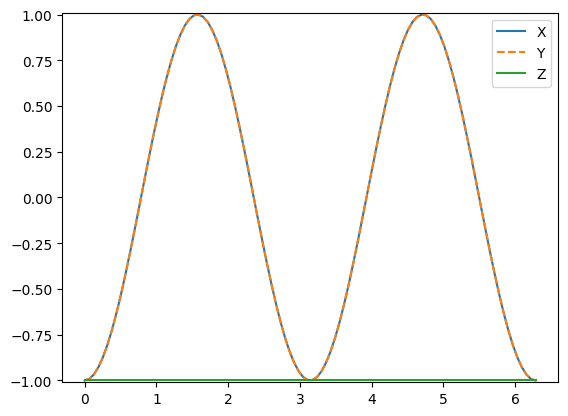

In [29]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=1)
measure_sparse = get_sparse_operator(measure_op, n_qubits=1)

# apply operator to vacuum to get a state
dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure_x = []
measure_y = []
measure_z = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('X0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_x.append(dot)

    generator = -1j * a * QubitOperator('Y0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_y.append(dot)

    generator = 1j * a * QubitOperator('Z0')
    sparse_gen = get_sparse_operator(generator, n_qubits=1)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_z.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure_x, label='X')
plt.plot(range_x, measure_y, '--', label='Y')
plt.plot(range_x, measure_z, label='Z')
plt.legend()

plt.ylim(-1.01, 1.01)

## One-qubit rotations

The implementation of exponential operators in Qiskit is done using rotation gates where $R_P(\phi)=e^{-i\phi P/2}$, hence `rx(2*theta)`, `ry(2*theta)`, and `rz(2*theta)` implement the Pauli exponential with angle $\theta$. The `X` gate initializes the reference state.

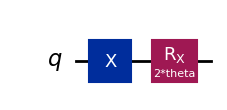

In [30]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_x = QuantumCircuit(1)

qc_x.x(0)

qc_x.rx(2*theta, 0)

qc_x.draw('mpl')

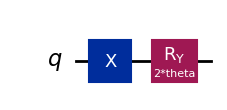

In [31]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_y = QuantumCircuit(1)
qc_y.x(0)

qc_y.ry(2*theta, 0)

qc_y.draw('mpl')

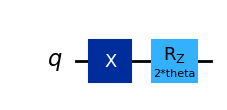

In [32]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_z = QuantumCircuit(1)
qc_z.x(0)

qc_z.rz(2*theta, 0)

qc_z.draw('mpl')

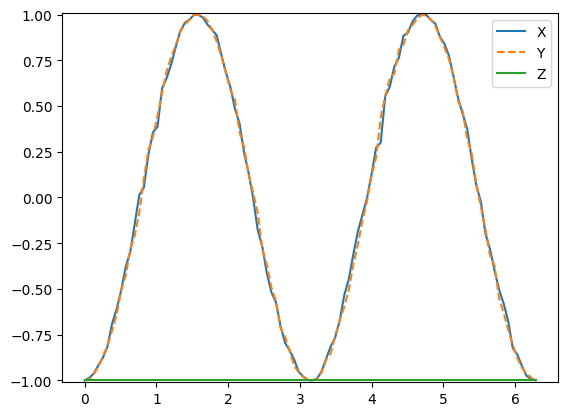

In [33]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    dot_x = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a])

        # change of basis
        #qc_meas.h(0)  # measure X
        #qc_meas.rx(np.pi / 2, 0)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_0 = counts.get('0', 0)/n_shots
        prob_1 = counts.get('1', 0)/n_shots

        measure = (+1 * prob_0
                   -1 * prob_1)

        dot_x.append(measure)

    return dot_x


value_x = get_expectation(qc_x)
value_y = get_expectation(qc_y)
value_z = get_expectation(qc_z)


import matplotlib.pyplot as plt

plt.plot(range_x, value_x, label='X')
plt.plot(range_x, value_y, '--', label='Y')
plt.plot(range_x, value_z, label='Z')

plt.ylim(-1.01, 1.01)
plt.legend()


## Two-qubit Pauli strings

Two-qubit Pauli strings are implemented in an analogous way. For this examaple we will implement the generators $X_0X_1$, $Y_0Y_1$, and $Z_0Z_1$ for the exponential operators, use the initial state obtained by applying $X_0 X_1$ on the vacuum and characterize the states by measuring the expectation value of $X_0 Y_1$.

In [34]:
initial_state = QubitOperator('X0 X1')
measure_op = QubitOperator('X0 Y1')

initial_sparse:  1.0


(-1.01, 1.01)

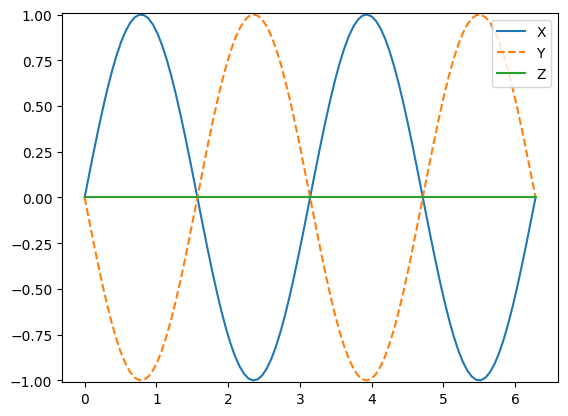

In [35]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=2)
measure_sparse = get_sparse_operator(measure_op, n_qubits=2)


dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure_x = []
measure_y = []
measure_z = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('X0 X1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_x.append(dot)

    generator = -1j * a * QubitOperator('Y0 Y1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_y.append(dot)

    generator = -1j * a * QubitOperator('Z0 Z1')
    sparse_gen = get_sparse_operator(generator, n_qubits=2)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_z.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure_x, label='X')
plt.plot(range_x, measure_y, '--', label='Y')
plt.plot(range_x, measure_z, label='Z')
plt.legend()

plt.ylim(-1.01, 1.01)

For multi-qubit Pauli string implementation we can use the **staircase algorithm**. First rotate every non-Z factor into the Z basis: $H X H=Z$ and $R_x(-\pi/2)Y R_x(\pi/2)=Z$. A CNOT ladder then computes the parity of the participating qubits onto one target qubit. Applying `rz(2*theta)` to that target realizes the phase $e^{-i\theta Z\otimes Z}$ in the rotated basis; reversing the CNOT ladder and basis changes restores the original basis.
The two-qubit circuits implement this recipe for $X_0X_1$, $Y_0Y_1$, and $Z_0Z_1$.

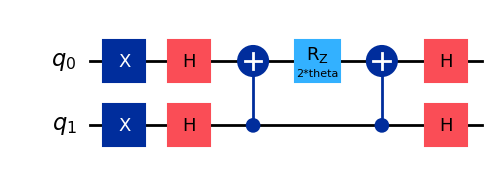

In [36]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_x = QuantumCircuit(2)

# reference state
qc_x.x(0)
qc_x.x(1)

# basis change
qc_x.h(0)
qc_x.h(1)

qc_x.cx(1, 0)
qc_x.rz(2*theta, 0)
qc_x.cx(1, 0)

# restore basis
qc_x.h(0)
qc_x.h(1)


qc_x.draw('mpl')

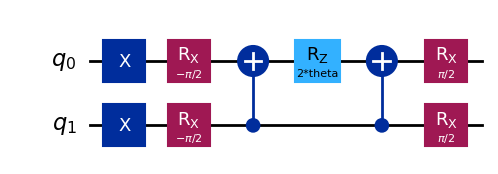

In [37]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_y = QuantumCircuit(2)

# reference state
qc_y.x(0)
qc_y.x(1)

# basis change
qc_y.rx(-np.pi / 2, 0)  # measure y
qc_y.rx(-np.pi / 2, 1)  # measure y

qc_y.cx(1, 0)
qc_y.rz(2*theta, 0)
qc_y.cx(1, 0)

# restore basis
qc_y.rx(np.pi / 2, 0)  # measure y
qc_y.rx(np.pi / 2, 1)  # measure y


qc_y.draw('mpl')

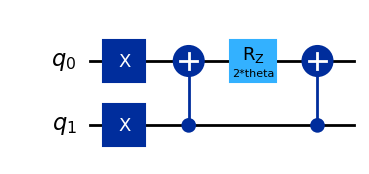

In [38]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_z = QuantumCircuit(2)

# reference state
qc_z.x(0)
qc_z.x(1)

qc_z.cx(1, 0)
qc_z.rz(2*theta, 0)
qc_z.cx(1, 0)

qc_z.draw('mpl')

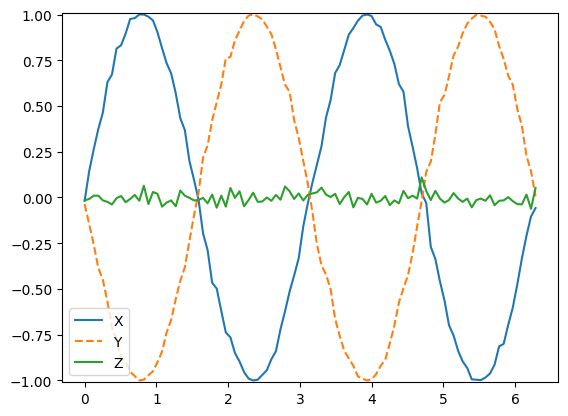

In [39]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    measures = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a]).copy()

        # change of basis
        qc_meas.h(0)  # measure X
        qc_meas.rx(np.pi / 2, 1)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_00 = counts.get('00', 0)/n_shots
        prob_01 = counts.get('01', 0)/n_shots
        prob_10 = counts.get('10', 0)/n_shots
        prob_11 = counts.get('11', 0)/n_shots

        # print(prob_00, prob_01, prob_10, prob_11)

        measure = (+1 * prob_11  # -1 * -1
                   -1 * prob_10  # -1 * +1
                   -1 * prob_01  # +1 * -1
                   +1 * prob_00) # +1 * +1

        measures.append(measure)

    return measures

value_x = get_expectation(qc_x)
value_y = get_expectation(qc_y)
value_z = get_expectation(qc_z)

import matplotlib.pyplot as plt

plt.plot(range_x, value_x, label='X')
plt.plot(range_x, value_y, '--', label='Y')
plt.plot(range_x, value_z, label='Z')

plt.ylim(-1.01, 1.01)
plt.legend()

- test using different operators for measurement and evolution and convince yourself that the algorithm is correct
- Test an example with 3 qubits

## Three-qubit example: $Y_0Y_1X_2$

The final example applies the same construction to a three-qubit Pauli string. The CNOT chain $2\rightarrow1\rightarrow0$ accumulates the Z-parity on qubit 0 after the Y and X basis changes. Its inverse uncomputes that parity after the RZ phase.

For a Pauli product measured in the Z basis, the outcome associated with bit string $b$ is

$$p(b)=(-1)^{b_0+b_1+\cdots+b_{n-1}},\qquad \langle P\rangle\approx\sum_b p(b)\,\Pr(b).$$

The explicit probability-weighted sum in the code is this parity estimator written out for all eight possible bit strings.

In [40]:
initial_state = QubitOperator('X1 X2')
measure_op = QubitOperator('Z0 Z1 Z2')

initial_sparse:  1.0


(-1.01, 1.01)

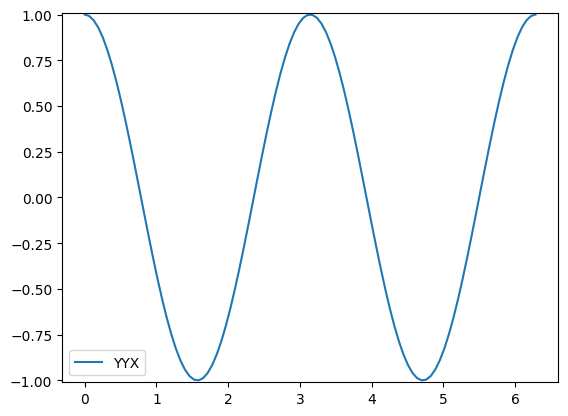

In [41]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply


initial_sparse = get_sparse_operator(initial_state, n_qubits=3)
measure_sparse = get_sparse_operator(measure_op, n_qubits=3)


dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:
    generator = -1j * a * QubitOperator('Y0 Y1 X2')
    sparse_gen = get_sparse_operator(generator, n_qubits=3)
    state = expm_multiply(sparse_gen, initial_sparse)
    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure.append(dot)

import matplotlib.pyplot as plt

plt.plot(range_x, measure, label='YYX')
plt.legend()

plt.ylim(-1.01, 1.01)

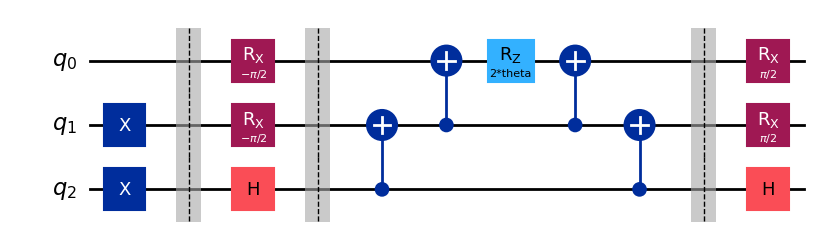

In [42]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc_yyx = QuantumCircuit(3)

# reference state
qc_yyx.x(1)
qc_yyx.x(2)

qc_yyx.barrier()

# basis change
qc_yyx.rx(-np.pi / 2, 0)  # measure y
qc_yyx.rx(-np.pi / 2, 1)  # measure y
qc_yyx.h(2)

qc_yyx.barrier()

qc_yyx.cx(2, 1)
qc_yyx.cx(1, 0)
qc_yyx.rz(2*theta, 0)
qc_yyx.cx(1, 0)
qc_yyx.cx(2, 1)

qc_yyx.barrier()

# restore basis
qc_yyx.h(2)
qc_yyx.rx(np.pi / 2, 1)  # measure y
qc_yyx.rx(np.pi / 2, 0)  # measure y

qc_yyx.draw('mpl')

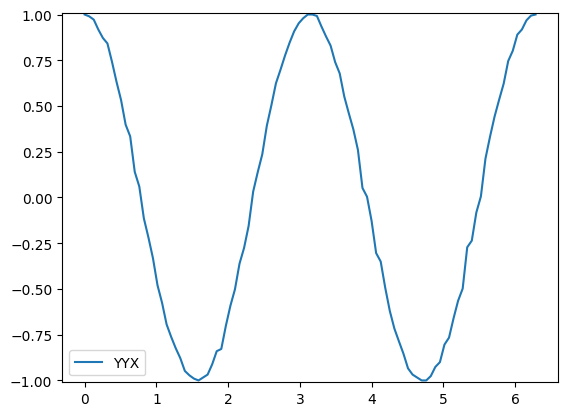

In [43]:
from qiskit.primitives import StatevectorSampler


def get_expectation(qc):
    measures = []
    range_x = np.linspace(0, 2*np.pi, 100)
    for a in range_x:

        # create circuit
        qc_meas = qc.assign_parameters([a]).copy()

        # change of basis
        #qc_meas.h(0)  # measure X
        #qc_meas.rx(np.pi / 2, 1)  # measure y

        # add measure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        n_shots = sum(counts.values())

        prob_000 = counts.get('000', 0)/n_shots
        prob_001 = counts.get('001', 0)/n_shots
        prob_010 = counts.get('010', 0)/n_shots
        prob_011 = counts.get('011', 0)/n_shots

        prob_100 = counts.get('100', 0)/n_shots
        prob_101 = counts.get('101', 0)/n_shots
        prob_110 = counts.get('110', 0)/n_shots
        prob_111 = counts.get('111', 0)/n_shots


        measure = (+1 * prob_011  # +1 * -1 * -1
                   -1 * prob_010  # +1 * -1 * +1
                   -1 * prob_001  # +1 * +1 * -1
                   +1 * prob_000  # +1 * +1 * +1

                   -1 * prob_111  # -1 * -1 * -1
                   +1 * prob_110  # -1 * -1 * +1
                   +1 * prob_101  # -1 * +1 * -1
                   -1 * prob_100  # -1 * +1 * +1

                   )

        measures.append(measure)

    return measures

value_yyx = get_expectation(qc_yyx)

import matplotlib.pyplot as plt

plt.plot(range_x, value_yyx, label='YYX')

plt.ylim(-1.01, 1.01)
plt.legend()

## Excercise
implement the operators $e^{-i\theta X_0} e^{-i\theta Z_0}$ and $e^{-i\theta Z_0} e^{-i\theta X_0}$ and observe the differences when applied to a reference state and measure in X, Y and Z. Are they the same? Why?

In [ ]:
import numpy as np
from scipy.sparse.linalg import expm, expm_multiply

initial_state = QubitOperator('')
initial_sparse = get_sparse_operator(initial_state, n_qubits=1)

# apply operator to vacuum to get a state
dot = (initial_sparse.T.conj() @ initial_sparse)[0, 0].real
print('initial_sparse: ', dot)

measure_x = []
measure_y = []
measure_z = []

range_x = np.linspace(0, 2*np.pi, 100)
for a in range_x:

    generator1 = -1j * a * QubitOperator('X0')
    generator2 = -1j * a * QubitOperator('Y0')
    sparse_gen1 = get_sparse_operator(generator1, n_qubits=1)
    sparse_gen2 = get_sparse_operator(generator2, n_qubits=1)
    state = expm_multiply(sparse_gen1, initial_sparse)
    state = expm_multiply(sparse_gen2, state)


    measure_op = QubitOperator('X0')
    measure_sparse = get_sparse_operator(measure_op, n_qubits=1)

    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_x.append(dot)

    measure_op = QubitOperator('Y0')
    measure_sparse = get_sparse_operator(measure_op, n_qubits=1)

    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_y.append(dot)

    measure_op = QubitOperator('Z0')
    measure_sparse = get_sparse_operator(measure_op, n_qubits=1)

    dot = (state.T.conj() @ measure_sparse @ state)[0, 0].real
    measure_z.append(dot)


import matplotlib.pyplot as plt

plt.plot(range_x, measure_x, label='X')
plt.plot(range_x, measure_y, '--', label='Y')
plt.plot(range_x, measure_z, label='Z')
plt.legend()

plt.ylim(-1.01, 1.01)

UsageError: Line magic function `%hide-input` not found.
